In [1]:
import pandas as pd

df = pd.read_csv("../data/demand_forecasting.csv")

df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,Snowy,1,92.02,Winter,0,229
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,Snowy,1,60.08,Winter,0,157
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,Snowy,0,85.19,Winter,0,52
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,Snowy,0,51.63,Winter,0,59


In [2]:
df.shape

(76000, 16)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76000 entries, 0 to 75999
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                76000 non-null  object 
 1   Store ID            76000 non-null  object 
 2   Product ID          76000 non-null  object 
 3   Category            76000 non-null  object 
 4   Region              76000 non-null  object 
 5   Inventory Level     76000 non-null  int64  
 6   Units Sold          76000 non-null  int64  
 7   Units Ordered       76000 non-null  int64  
 8   Price               76000 non-null  float64
 9   Discount            76000 non-null  int64  
 10  Weather Condition   76000 non-null  object 
 11  Promotion           76000 non-null  int64  
 12  Competitor Pricing  76000 non-null  float64
 13  Seasonality         76000 non-null  object 
 14  Epidemic            76000 non-null  int64  
 15  Demand              76000 non-null  int64  
dtypes: f

In [4]:
df.describe()

,Inventory Level,Units Sold,Units Ordered,Price,Discount,Promotion,Competitor Pricing,Epidemic,Demand
count,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000
mean,301.062842,88.827316,89.090645,67.726028,9.087039,0.328947,69.454029,0.200000,104.317158
std,226.510161,43.994525,162.404627,39.377899,7.475781,0.469834,40.943818,0.400003,46.964801
min,0.000000,0.000000,0.000000,4.740000,0.000000,0.000000,4.290000,0.000000,4.000000
25%,136.000000,58.000000,0.000000,31.997500,5.000000,0.000000,32.620000,0.000000,71.000000
50%,227.000000,84.000000,0.000000,64.500000,10.000000,0.000000,65.700000,0.000000,100.000000
75%,408.000000,114.000000,121.000000,95.830000,10.000000,1.000000,97.932500,0.000000,133.000000
max,2267.000000,426.000000,1616.000000,228.030000,25.000000,1.000000,261.220000,1.000000,430.000000


In [5]:
df.isnull().sum()

Date                  0
Store ID              0
Product ID            0
Category              0
Region                0
Inventory Level       0
Units Sold            0
Units Ordered         0
Price                 0
Discount              0
Weather Condition     0
Promotion             0
Competitor Pricing    0
Seasonality           0
Epidemic              0
Demand                0
dtype: int64

In [6]:
for col in ['Category', 'Region', 'Weather Condition', 'Seasonality']:
    print(f"\n{col}:")
    print(df[col].unique())


Category:
['Electronics' 'Clothing' 'Groceries' 'Toys' 'Furniture']

Region:
['North' 'South' 'East' 'West']

Weather Condition:
['Snowy' 'Cloudy' 'Sunny' 'Rainy']

Seasonality:
['Winter' 'Spring' 'Summer' 'Autumn']


In [7]:
df[['Price', 'Demand', 'Units Sold', 'Discount', 'Competitor Pricing']].corr()

,Price,Demand,Units Sold,Discount,Competitor Pricing
Price,1.000000,-0.023461,-0.014506,-0.094136,0.976648
Demand,-0.023461,1.000000,0.833421,0.224723,-0.023036
Units Sold,-0.014506,0.833421,1.000000,0.183523,-0.013989
Discount,-0.094136,0.224723,0.183523,1.000000,-0.092066
Competitor Pricing,0.976648,-0.023036,-0.013989,-0.092066,1.000000


In [8]:
df[['Price', 'Demand', 'Units Sold', 'Discount', 'Competitor Pricing']].describe()

,Price,Demand,Units Sold,Discount,Competitor Pricing
count,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000
mean,67.726028,104.317158,88.827316,9.087039,69.454029
std,39.377899,46.964801,43.994525,7.475781,40.943818
min,4.740000,4.000000,0.000000,0.000000,4.290000
25%,31.997500,71.000000,58.000000,5.000000,32.620000
50%,64.500000,100.000000,84.000000,10.000000,65.700000
75%,95.830000,133.000000,114.000000,10.000000,97.932500
max,228.030000,430.000000,426.000000,25.000000,261.220000


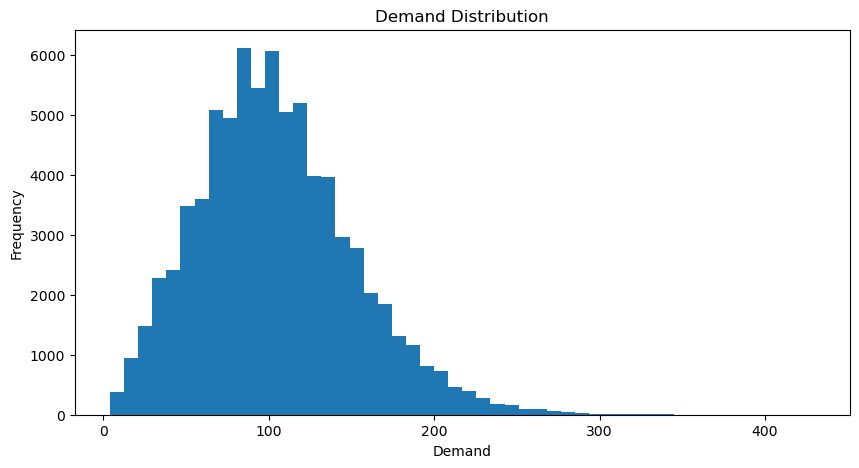

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(df['Demand'], bins=50)
plt.xlabel('Demand')
plt.ylabel('Frequency')
plt.title('Demand Distribution')
plt.show()

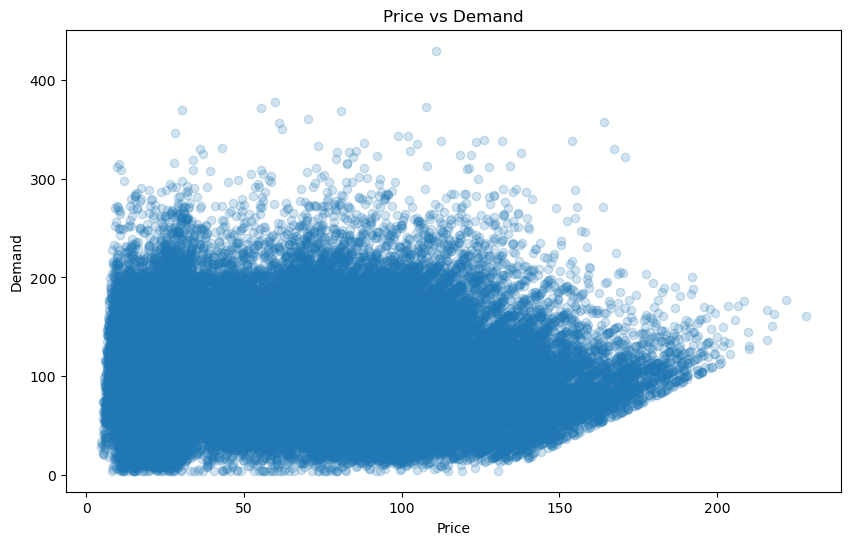

In [10]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df['Price'],
    df['Demand'],
    alpha=0.2
)

plt.xlabel('Price')
plt.ylabel('Demand')
plt.title('Price vs Demand')

plt.show()

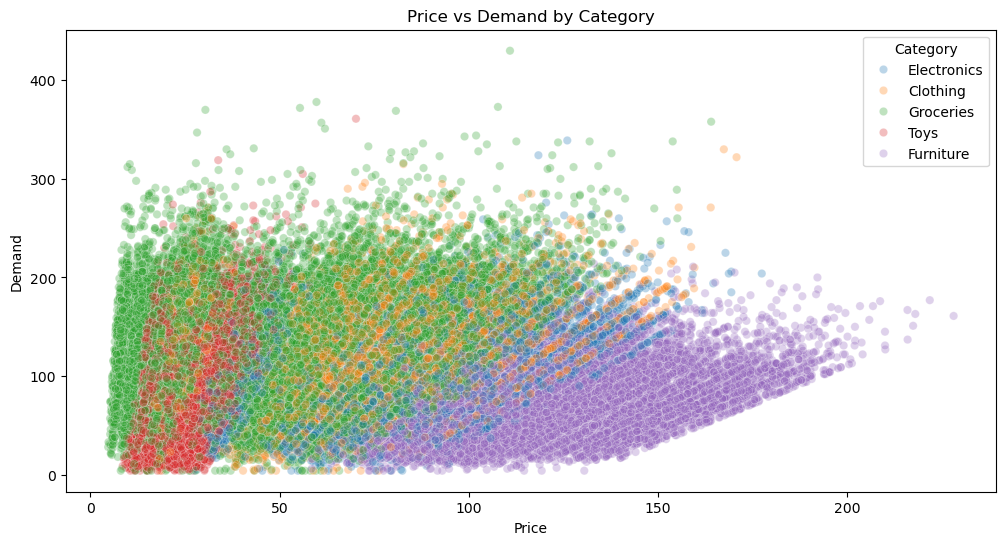

In [11]:
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=df,
    x='Price',
    y='Demand',
    hue='Category',
    alpha=0.3
)

plt.title('Price vs Demand by Category')
plt.show()

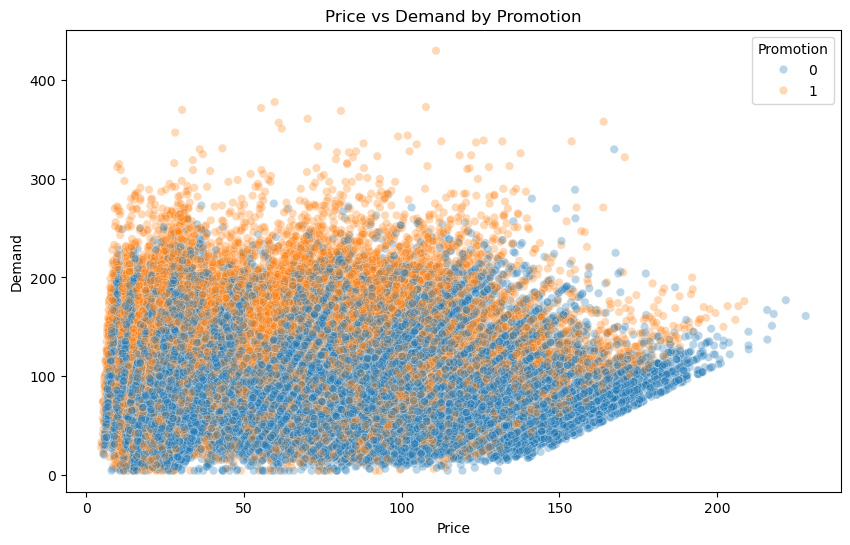

In [12]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Price',
    y='Demand',
    hue='Promotion',
    alpha=0.3
)

plt.title('Price vs Demand by Promotion')
plt.show()

In [13]:
df['Date'] = pd.to_datetime(df['Date'])

In [14]:
df['Date'].min(), df['Date'].max()

(Timestamp('2022-01-01 00:00:00'), Timestamp('2024-01-30 00:00:00'))

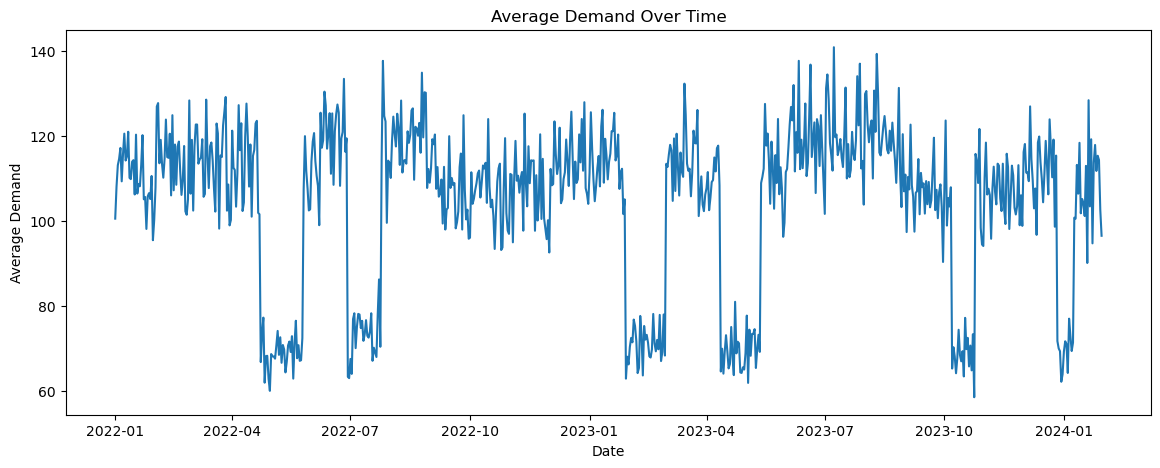

In [15]:
daily_demand = df.groupby('Date')['Demand'].mean()

plt.figure(figsize=(14, 5))

plt.plot(daily_demand)

plt.xlabel('Date')
plt.ylabel('Average Demand')
plt.title('Average Demand Over Time')

plt.show()

In [16]:
season_demand = df.groupby('Seasonality')['Demand'].mean()

print(season_demand)

Seasonality
Autumn    103.422967
Spring     97.703098
Summer    112.855380
Winter    103.406190
Name: Demand, dtype: float64


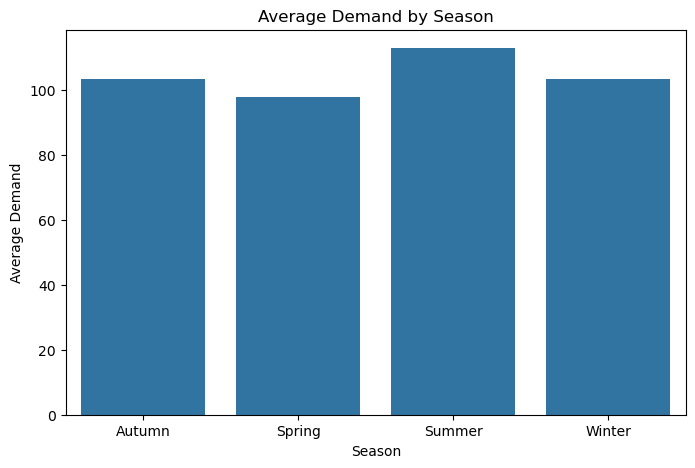

In [17]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=season_demand.index,
    y=season_demand.values
)

plt.xlabel('Season')
plt.ylabel('Average Demand')
plt.title('Average Demand by Season')

plt.show()

In [18]:
df['Price_Bin'] = pd.cut(
    df['Price'],
    bins=[0, 25, 50, 75, 100, 125, 150, 200, 250]
)

price_demand = (
    df.groupby('Price_Bin', observed=True)['Demand']
      .mean()
)

print(price_demand)

Price_Bin
(0, 25]        98.624272
(25, 50]      109.116817
(50, 75]      108.502090
(75, 100]     105.573623
(100, 125]    100.220553
(125, 150]     96.336187
(150, 200]     99.848214
(200, 250]    145.190476
Name: Demand, dtype: float64


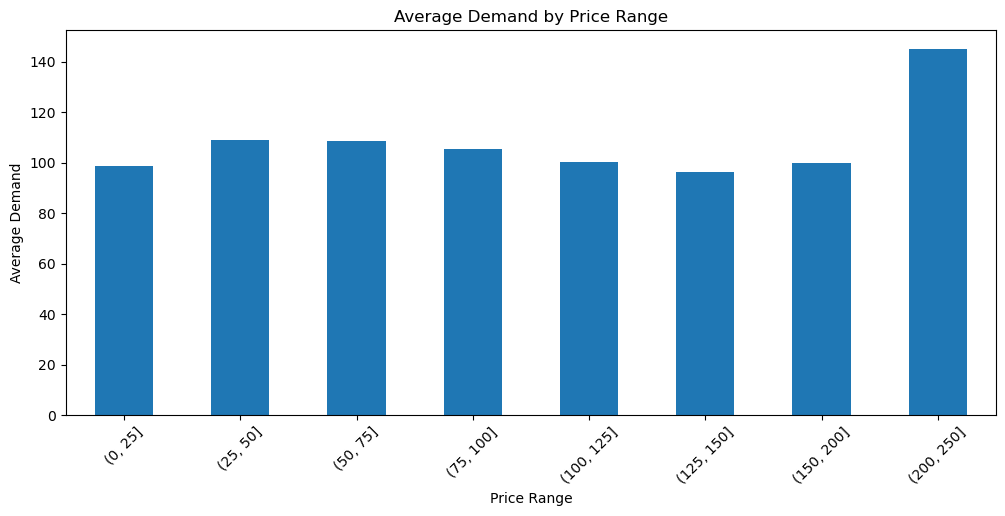

In [19]:
plt.figure(figsize=(12, 5))

price_demand.plot(kind='bar')

plt.xlabel('Price Range')
plt.ylabel('Average Demand')
plt.title('Average Demand by Price Range')

plt.xticks(rotation=45)

plt.show()

In [20]:
price_analysis = (
    df.groupby('Price_Bin', observed=True)
      .agg(
          Avg_Demand=('Demand', 'mean'),
          Records=('Demand', 'size')
      )
)

price_analysis

,Avg_Demand,Records
Price_Bin,,
"(0, 25]",98.624272,13052
"(25, 50]",109.116817,15597
"(50, 75]",108.502090,16266
"(75, 100]",105.573623,14323
"(100, 125]",100.220553,10052
"(125, 150]",96.336187,4673
"(150, 200]",99.848214,2016
"(200, 250]",145.190476,21


In [21]:
promotion_analysis = (
    df.groupby('Promotion')['Demand']
      .agg(['mean', 'median', 'count'])
)

promotion_analysis

,mean,median,count
Promotion,,,
0,95.026843,92.0,51000
1,123.269400,120.0,25000


In [22]:
category_analysis = (
    df.groupby('Category')['Demand']
      .agg(['mean', 'median', 'count'])
      .sort_values('mean', ascending=False)
)

category_analysis

,mean,median,count
Category,,,
Groceries,120.976447,116.0,30400
Clothing,112.619737,109.0,12160
Electronics,97.482018,95.0,9120
Toys,92.606955,92.0,10640
Furniture,73.581140,72.0,13680


In [23]:
df[['Demand', 'Units Sold', 'Units Ordered']].describe()

,Demand,Units Sold,Units Ordered
count,76000.000000,76000.000000,76000.000000
mean,104.317158,88.827316,89.090645
std,46.964801,43.994525,162.404627
min,4.000000,0.000000,0.000000
25%,71.000000,58.000000,0.000000
50%,100.000000,84.000000,0.000000
75%,133.000000,114.000000,121.000000
max,430.000000,426.000000,1616.000000


In [24]:
df['Demand_minus_Sold'] = df['Demand'] - df['Units Sold']

df['Demand_minus_Sold'].describe()

count    76000.000000
mean        15.489842
std         26.404353
min        -68.000000
25%         -2.000000
50%         11.000000
75%         27.000000
max        316.000000
Name: Demand_minus_Sold, dtype: float64

In [25]:
df['Demand_minus_Sold'] = df['Demand'] - df['Units Sold']

df['Demand_minus_Sold'].describe()

count    76000.000000
mean        15.489842
std         26.404353
min        -68.000000
25%         -2.000000
50%         11.000000
75%         27.000000
max        316.000000
Name: Demand_minus_Sold, dtype: float64

In [26]:
df['Price_Difference'] = (
    df['Price'] - df['Competitor Pricing']
)

df['Price_Difference'].describe()

count    76000.000000
mean        -1.728002
std          8.817663
min        -45.380000
25%         -7.230000
50%          0.030000
75%          3.750000
max         33.090000
Name: Price_Difference, dtype: float64

In [27]:
df.groupby(
    pd.qcut(df['Price_Difference'], 5)
)['Demand'].mean()

C:\Users\HP\AppData\Local\Temp\ipykernel_9536\2941515581.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(


Price_Difference
(-45.381, -8.96]    103.571898
(-8.96, -3.24]      106.686665
(-3.24, 1.28]       102.021882
(1.28, 5.05]        105.148748
(5.05, 33.09]       104.160339
Name: Demand, dtype: float64